# **1-Leitura dos vídeos e primeira deteção com YOLO**

**Projeto:** Sistema de Deteção Automática de Eventos de Futebol (FootAR)

**Objetivo deste notebook:** confirmar que os vídeos da Liga Portugal 24/25 são lidos corretamente e aplicar uma primeira deteção de pessoas e bola com YOLO. É a base para, nos passos seguintes, analisar os movimentos dos jogadores e do árbitro e detetar faltas, foras de jogo, penáltis, etc...

## 1.1 Definição dos caminhos do projeto


Esta célula indica ao Python onde estão as pastas do projeto:

| Variável | Pasta | Conteúdo |
|---|---|---|
| `BASE` | `FOOTAR_DETECAO_DE_EVENTOS` | raiz do projeto |
| `PASTA_VIDEOS` | `videos` | clips da Liga Portugal 24/25 fornecidos pela FootAR |
| `PASTA_SAIDA` | `resultados/passo1` | imagens com as deteções geradas neste passo |

A pasta de resultados é criada automaticamente, se ainda não existir.
O `print` final confirma se a pasta dos vídeos foi encontrada (`True`).

In [2]:
from pathlib import Path

BASE = Path(r"C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS")

PASTA_VIDEOS = BASE / "videos"
PASTA_SAIDA  = BASE / "resultados" / "passo1"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

print("Pasta de vídeos existe?", PASTA_VIDEOS.exists())

Pasta de vídeos existe? True


## 1.2 Listagem dos vídeos disponíveis

Percorre a pasta `videos` e seleciona todos os ficheiros de vídeo (`.mp4`, `.mov`, `.mkv`, `.avi`), mostrando o nome e o tamanho de cada um.

Os nomes dos ficheiros seguem o formato `Jornada-Equipa1-Equipa2_Resultado.mp4` (ex.: `J10-Porto-Estoril_1-0.mp4`). Cada clip corresponde ao momento de um golo, identificado pelo resultado após esse golo.



In [3]:
EXTENSOES = {".mp4", ".mov", ".mkv", ".avi"}
videos = sorted(p for p in PASTA_VIDEOS.iterdir() if p.suffix.lower() in EXTENSOES)

print(f"Encontrei {len(videos)} vídeo(s):")
for v in videos:
    print(" -", v.name, f"({v.stat().st_size / 1e6:.1f} MB)")

Encontrei 60 vídeo(s):
 - J1-Braga-Estrela_1-0.mp4 (8.5 MB)
 - J1-Braga-Estrela_1-1.mp4 (9.2 MB)
 - J1-Sporting-RioAve_1-0.mp4 (8.2 MB)
 - J1-Sporting-RioAve_2-0.mp4 (6.8 MB)
 - J1-Sporting-RioAve_3-0.mp4 (7.1 MB)
 - J1-Sporting-RioAve_3-1.mp4 (9.6 MB)
 - J10-Porto-Estoril_1-0.mp4 (6.5 MB)
 - J10-Porto-Estoril_2-0.mp4 (6.3 MB)
 - J10-Porto-Estoril_3-0.mp4 (6.7 MB)
 - J10-Porto-Estoril_4-0.mp4 (4.8 MB)
 - J10-RioAve-CasaPia_0-1.mp4 (4.9 MB)
 - J10-RioAve-CasaPia_1-1.mp4 (4.2 MB)
 - J10-RioAve-CasaPia_1-2.mp4 (7.4 MB)
 - J10-RioAve-CasaPia_2-2.mp4 (4.4 MB)
 - J10-Sporting-EstrelaAmadora_1-0.mp4 (5.8 MB)
 - J10-Sporting-EstrelaAmadora_2-0.mp4 (4.5 MB)
 - J10-Sporting-EstrelaAmadora_2-1.mp4 (8.1 MB)
 - J10-Sporting-EstrelaAmadora_4-1.mp4 (3.6 MB)
 - J10-Sporting-EstrelaAmadora_5-1.mp4 (5.6 MB)
 - J11-Benfica-Porto_1-0.mp4 (9.9 MB)
 - J11-Benfica-Porto_1-1.mp4 (5.3 MB)
 - J11-Benfica-Porto_2-1.mp4 (8.3 MB)
 - J11-Benfica-Porto_3-1.mp4 (10.3 MB)
 - J11-Boavista-RioAve_0-1.mp4 (6.1 MB)
 - J11

## 1.3 Primeira deteção com YOLO

Para cada vídeo, é extraído um frame e aplicado o modelo **YOLOv8m pré-treinado no dataset COCO**.

- **Frame escolhido:** o do minuto 1 ou, se o clip for mais curto, o frame do meio.
- **Classes relevantes do COCO:** `person` (pessoas) e `sports ball` (bola).
- **Limiar de confiança:** 0,3, ou seja, só são mostradas deteções com pelo menos 30% de precisão.
- **Resultado:** uma imagem por vídeo, com as caixas desenhadas, gravada em `resultados/passo1`.

**Limitação esperada:** o modelo genérico não distingue jogadores, guarda-redes e árbitro, porque deteta todos como `person`. Para detetar faltas e penáltis é essencial identificar o árbitro, o que justifica o uso do modelo treinado com o dataset da FootAR no Passo 2.

In [4]:
import cv2
from ultralytics import YOLO

model = YOLO("yolov8m.pt")   # na 1.ª vez descarrega o modelo (~50 MB)

for video in videos:
    cap = cv2.VideoCapture(str(video))
    if not cap.isOpened():
        print(f"✗ {video.name}: não abriu")
        continue

    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    alvo = min(int(fps * 60), total // 2) if total > 0 else 0
    cap.set(cv2.CAP_PROP_POS_FRAMES, alvo)
    ok, frame = cap.read()
    cap.release()

    if not ok:
        print(f"✗ {video.name}: abriu mas não leu frames")
        continue

    res = model(frame, conf=0.3, verbose=False)[0]
    classes = [model.names[int(c)] for c in res.boxes.cls]
    print(f"✓ {video.name}: {fps:.0f} fps, {total} frames ({total/fps:.1f} s), "
          f"{frame.shape[1]}x{frame.shape[0]} | pessoas={classes.count('person')}, "
          f"bola={classes.count('sports ball')}")

    ok, buf = cv2.imencode(".jpg", res.plot())        # funciona com acentos no caminho
    buf.tofile(str(PASTA_SAIDA / f"{video.stem}_passo1.jpg"))

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\simao\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
✓ J1-Braga-Estrela_1-0.mp4: 25 fps, 258 frames (10.3 s), 1920x1080 | pessoas=15, bola=0
✓ J1-Braga-Estrela_1-1.mp4: 25 fps, 281 frames (11.3 s), 1920x1080 | pessoas=16, bola=0
✓ J1-Sporting-RioAve_1-0.mp4: 25 fps, 290 frames (11.6 s), 1920x1080 | pessoas=8, bola=0
✓ J1-Sporting-RioAve_2-0.mp4: 25 fps, 204 frames (8.2 s), 1920x1080 | pessoas=12, bola=1
✓ J1-Sporting-RioAve_3-0.mp4: 25 fps, 190 frames (7.7 s), 1920x1080 | pessoas=15, bola=0
✓ J1-Sporting-RioAve_3-1.mp4: 25 fps, 269 frames (10.8 s), 1920x1080 | pessoas=6, bola=0
✓ J10-Porto-Estoril_1-0.mp4: 25 fps, 203 frames (8.1 s), 1920x1080 | pessoas=14, bola=0
✓ J10-Porto-Estoril_2-0.mp4: 25 fps, 163 frames (6.6 s), 1920x1080 | pe

## 1.4 Visualização de um resultado

Mostra no notebook a imagem com as deteções do primeiro vídeo, para inspecionar a qualidade da deteção.

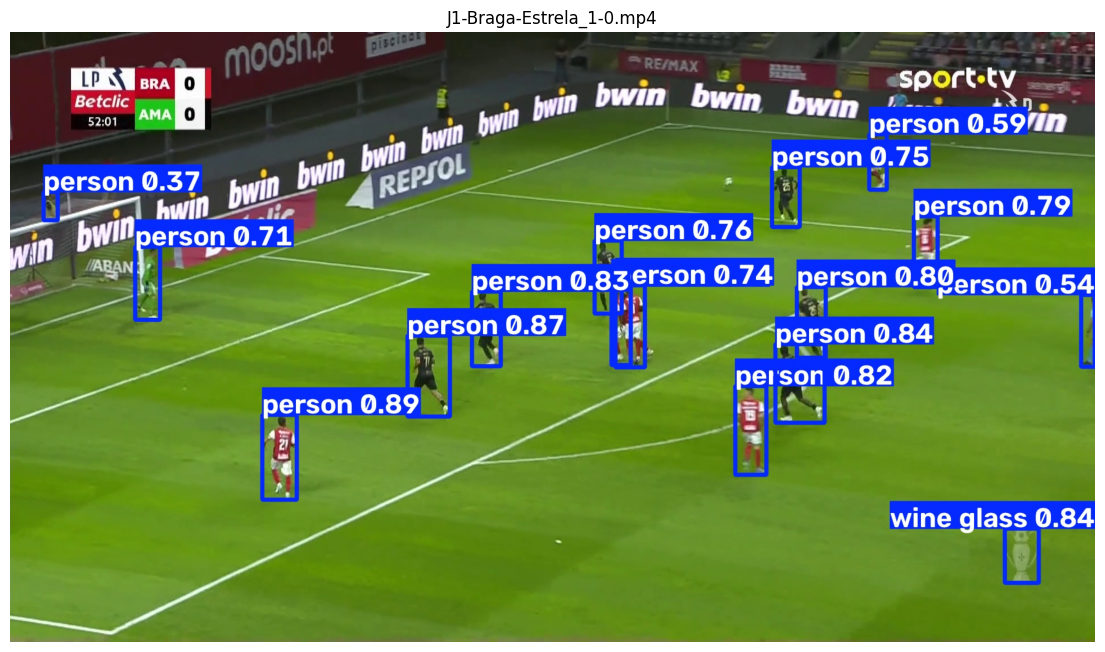

In [5]:
import matplotlib.pyplot as plt
import numpy as np

img_path = PASTA_SAIDA / f"{videos[0].stem}_passo1.jpg"
img = cv2.imdecode(np.fromfile(str(img_path), dtype=np.uint8), cv2.IMREAD_COLOR)

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(videos[0].name)
plt.axis("off")
plt.show()

## 1.5 Conclusões do Passo 1

- Os clips da Liga Portugal 24/25 foram lidos corretamente com OpenCV.
- O YOLOv8m genérico (COCO) deteta a maioria dos intervenientes (~15 por frame), com ####confiança entre 0,37 e 0,89.

**Limitações observadas:**
1. **Sem distinção de papéis:** jogadores, guarda-redes e árbitro são todos `person`. A identificação do árbitro é indispensável para detetar faltas, cartões e penáltis.
2. **Bola não detetada:** a bola ocupa poucos píxeis e o modelo genérico, a 640 px, não a encontra.
3. **Falsos positivos em grafismos:** o troféu do grafismo da transmissão foi detetado como `wine glass`.
4. **Confiança baixa em jogadores distantes.**

**Próximo passo:** treinar o YOLO com o dataset da FootAR (Roboflow), que tem as classes `player`, `goalkeeper`, `referee` e `ball` e imagens destas transmissões.